# 03 — Aprendizaje supervisado: Naive Bayes

**Escenario 4:** Efectividad de campañas de marketing
**Dataset:** `data/processed/bank_clean.csv` (generado en el notebook 02)

**Objetivo:** predecir si un cliente va a responder de forma positiva (`y = 1`, contrata el depósito) o negativa (`y = 0`) a la campaña, usando sus características y los resultados de contactos anteriores.

## 1. Fundamento teórico

### Teorema de Bayes

Naive Bayes es un clasificador probabilístico que se basa en el teorema de Bayes. Calcula la probabilidad de que un cliente pertenezca a una clase $C$ (acepta o no acepta) dadas sus características $X = (x_1, x_2, \dots, x_n)$:

$$P(C \mid X) = \frac{P(X \mid C)\,P(C)}{P(X)}$$

donde:

- $P(C \mid X)$: probabilidad **posterior**, la probabilidad de la clase sabiendo las características del cliente.
- $P(X \mid C)$: **verosimilitud**, qué tan probable es ver esas características en esa clase.
- $P(C)$: probabilidad **a priori** de la clase (por ejemplo, 11,3% de los clientes aceptan).
- $P(X)$: evidencia, es igual para todas las clases así que no afecta la decisión.

### Supuesto "ingenuo" (naive)

El modelo supone que todas las variables son **independientes entre sí** dentro de cada clase. Así la verosimilitud se puede calcular como una multiplicación:

$$P(X \mid C) = \prod_{i=1}^{n} P(x_i \mid C)$$

Este supuesto casi nunca se cumple en la realidad (en el EDA se vio que `emp.var.rate`, `euribor3m` y `nr.employed` están muy correlacionadas), pero aun así el modelo suele funcionar bien en la práctica.

### Variante usada: Gaussian Naive Bayes

Se usa **GaussianNB**, que supone que cada variable sigue una distribución normal dentro de cada clase:

$$P(x_i \mid C) = \frac{1}{\sqrt{2\pi\sigma_{C,i}^2}} \exp\left(-\frac{(x_i - \mu_{C,i})^2}{2\sigma_{C,i}^2}\right)$$

donde $\mu_{C,i}$ y $\sigma_{C,i}^2$ son la media y la varianza de la variable $i$ en la clase $C$, calculadas con los datos de entrenamiento.

### Regla de decisión

El modelo elige la clase con mayor probabilidad posterior:

$$\hat{y} = \arg\max_{C} \; P(C) \prod_{i=1}^{n} P(x_i \mid C)$$

En la práctica se trabaja con logaritmos para evitar números demasiado pequeños:

$$\hat{y} = \arg\max_{C} \left[ \log P(C) + \sum_{i=1}^{n} \log P(x_i \mid C) \right]$$

### Hiperparámetro: `var_smoothing`

Es un valor pequeño que se suma a todas las varianzas para evitar divisiones entre cero y hacer el modelo más estable. Por defecto vale $10^{-9}$ y más adelante se prueban otros valores.

### ¿Por qué GaussianNB y no otra variante?

- **MultinomialNB** está pensado para conteos (por ejemplo, palabras en un texto) y no acepta valores negativos.
- **BernoulliNB** solo trabaja con variables binarias, y se perdería la información de variables como `age` o `euribor3m`.
- **GaussianNB** acepta variables continuas, que son las más importantes en este dataset.

## 2. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

df = pd.read_csv("../data/processed/bank_clean.csv")
print("Tamaño:", df.shape)

Tamaño: (41176, 42)


## 3. Variables predictoras y variable objetivo

- **X:** las 41 variables predictoras (datos del cliente, campañas anteriores, contexto económico y variables codificadas).
- **y:** si el cliente aceptó (1) o no (0).

In [2]:
X = df.drop(columns=["y"])
y = df["y"]
print("Variables predictoras:", X.shape[1])
print("Distribución de y:")
print(y.value_counts(normalize=True).mul(100).round(2))

Variables predictoras: 41
Distribución de y:
y
0    88.73
1    11.27
Name: proportion, dtype: float64


## 4. Separación en entrenamiento y prueba

Se separa 80% para entrenamiento y 20% para prueba. Se usa `stratify=y` para que las dos partes tengan el mismo porcentaje de clientes que aceptan (11,3%). Sin esto, por el desbalance, el conjunto de prueba podría quedar con muy pocos casos positivos.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]:,} registros | % y=1: {y_train.mean()*100:.2f}%")
print(f"Prueba:        {X_test.shape[0]:,} registros | % y=1: {y_test.mean()*100:.2f}%")

Entrenamiento: 32,940 registros | % y=1: 11.27%
Prueba:        8,236 registros | % y=1: 11.27%


## 5. Modelo base de comparación

Antes de entrenar Naive Bayes se prueba un modelo "tonto" que siempre predice la clase más común (`no`). Sirve para tener una referencia: si Naive Bayes no supera a este modelo, no está aprendiendo nada útil.

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
print(f"Accuracy:  {accuracy_score(y_test, y_dummy):.4f}")
print(f"Recall:    {recall_score(y_test, y_dummy):.4f}")
print(f"F1-score:  {f1_score(y_test, y_dummy):.4f}")

Accuracy:  0.8873
Recall:    0.0000
F1-score:  0.0000


El modelo base tiene casi **89% de accuracy** sin detectar a **ningún** cliente que acepta (recall = 0). Esto confirma lo que se vio en el EDA: por el desbalance, el accuracy no sirve para evaluar este problema y hay que fijarse en recall, precision, F1 y ROC-AUC.

## 6. Entrenamiento del modelo

Se usa un `Pipeline` que primero estandariza los datos y luego entrena GaussianNB. Así el `StandardScaler` aprende la media y desviación **solo del conjunto de entrenamiento**, y después aplica esa misma transformación al de prueba. De esta forma no se filtra información del test al entrenamiento.

In [5]:
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("nb", GaussianNB()),
])
modelo.fit(X_train, y_train)

nb = modelo.named_steps["nb"]
print("Probabilidades a priori P(C) aprendidas:")
print(f"  P(y=0) = {nb.class_prior_[0]:.4f}")
print(f"  P(y=1) = {nb.class_prior_[1]:.4f}")

Probabilidades a priori P(C) aprendidas:
  P(y=0) = 0.8873
  P(y=1) = 0.1127


## 7. Evaluación del modelo

In [6]:
y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]

def metricas(y_real, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred),
        "recall": recall_score(y_real, y_pred),
        "f1": f1_score(y_real, y_pred),
        "roc_auc": roc_auc_score(y_real, y_proba),
    }

m_base = metricas(y_test, y_pred, y_proba)
pd.Series(m_base).round(4).to_frame("GaussianNB (umbral 0.5)")

,GaussianNB (umbral 0.5)
accuracy,0.8706
precision,0.4278
recall,0.4407
f1,0.4342
roc_auc,0.7777


In [7]:
print(classification_report(y_test, y_pred, target_names=["No acepta (0)", "Acepta (1)"]))

               precision    recall  f1-score   support

No acepta (0)       0.93      0.93      0.93      7308
   Acepta (1)       0.43      0.44      0.43       928

     accuracy                           0.87      8236
    macro avg       0.68      0.68      0.68      8236
 weighted avg       0.87      0.87      0.87      8236



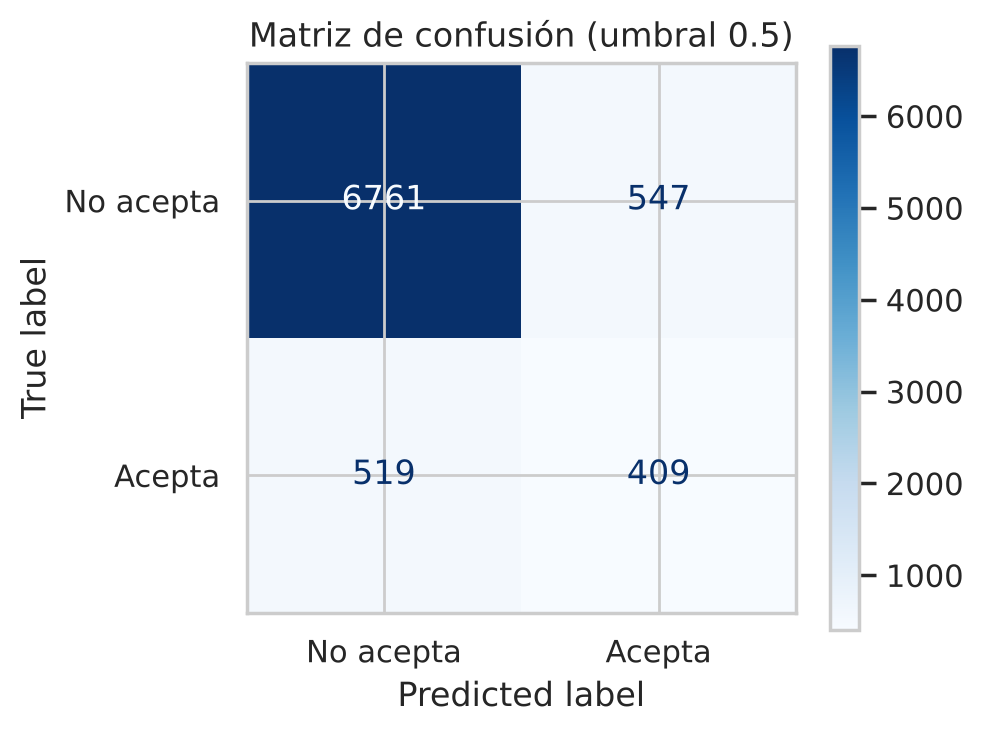

Verdaderos negativos (TN): 6761  -> no aceptan y el modelo acertó
Falsos positivos (FP):     547  -> el modelo dijo que aceptan pero no
Falsos negativos (FN):     519  -> sí aceptan pero el modelo no los detectó
Verdaderos positivos (TP): 409  -> aceptan y el modelo acertó


In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No acepta", "Acepta"]).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusión (umbral 0.5)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Verdaderos negativos (TN): {tn}  -> no aceptan y el modelo acertó")
print(f"Falsos positivos (FP):     {fp}  -> el modelo dijo que aceptan pero no")
print(f"Falsos negativos (FN):     {fn}  -> sí aceptan pero el modelo no los detectó")
print(f"Verdaderos positivos (TP): {tp}  -> aceptan y el modelo acertó")

### Fórmulas de las métricas

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN}$$

$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision:** de los clientes que el modelo dice que van a aceptar, cuántos realmente aceptan.
- **Recall:** de todos los clientes que aceptan, cuántos logra encontrar el modelo.
- **F1:** equilibrio entre precision y recall.
- **ROC-AUC:** mide qué tan bien el modelo ordena a los clientes según su probabilidad de aceptar (0,5 = al azar, 1 = perfecto).

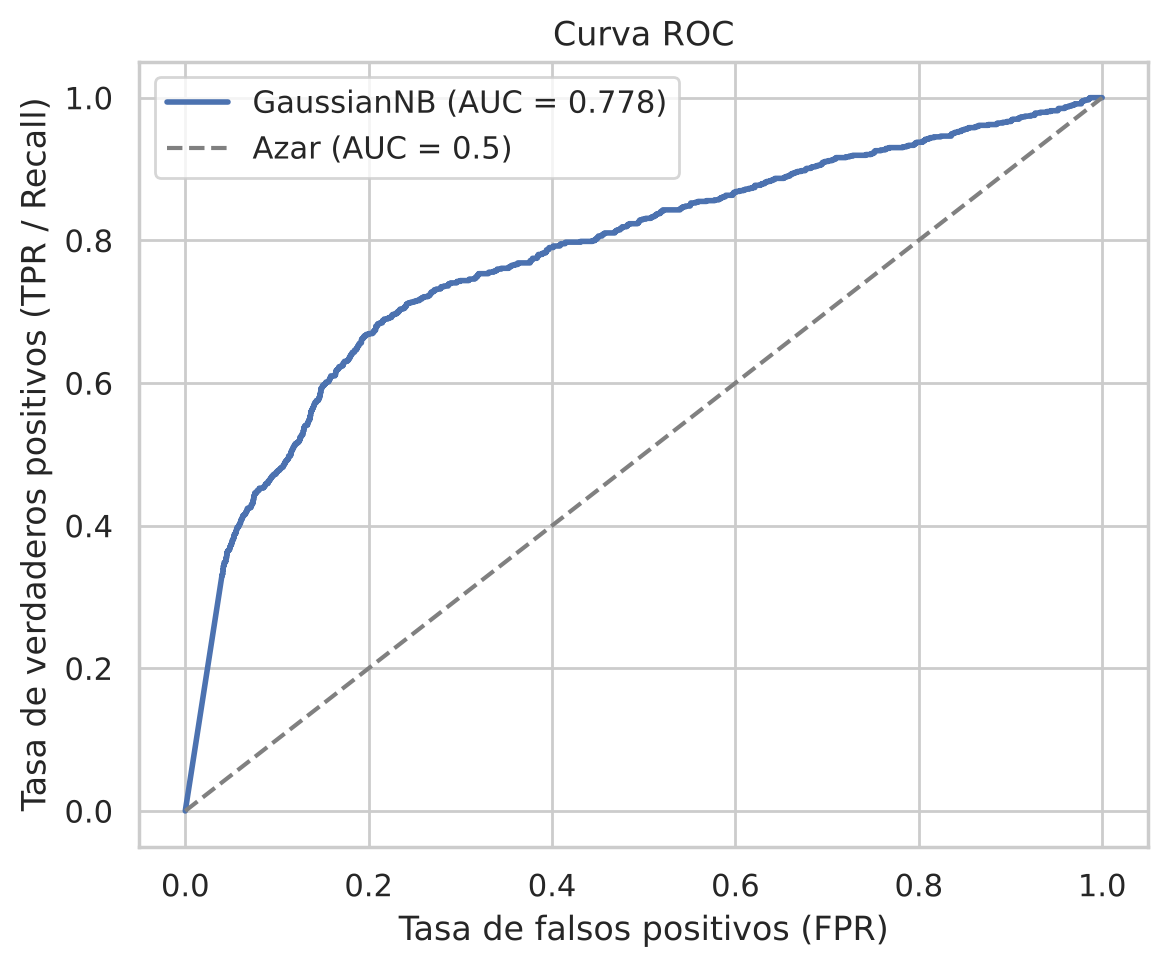

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"GaussianNB (AUC = {m_base['roc_auc']:.3f})", lw=2)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR / Recall)")
ax.set_title("Curva ROC")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Análisis del umbral de decisión

Por defecto el modelo dice "acepta" cuando la probabilidad es mayor a 0,5. Pero ese valor no tiene por qué ser el mejor, sobre todo con clases desbalanceadas. Se prueban distintos umbrales para ver cómo cambian precision, recall y F1.

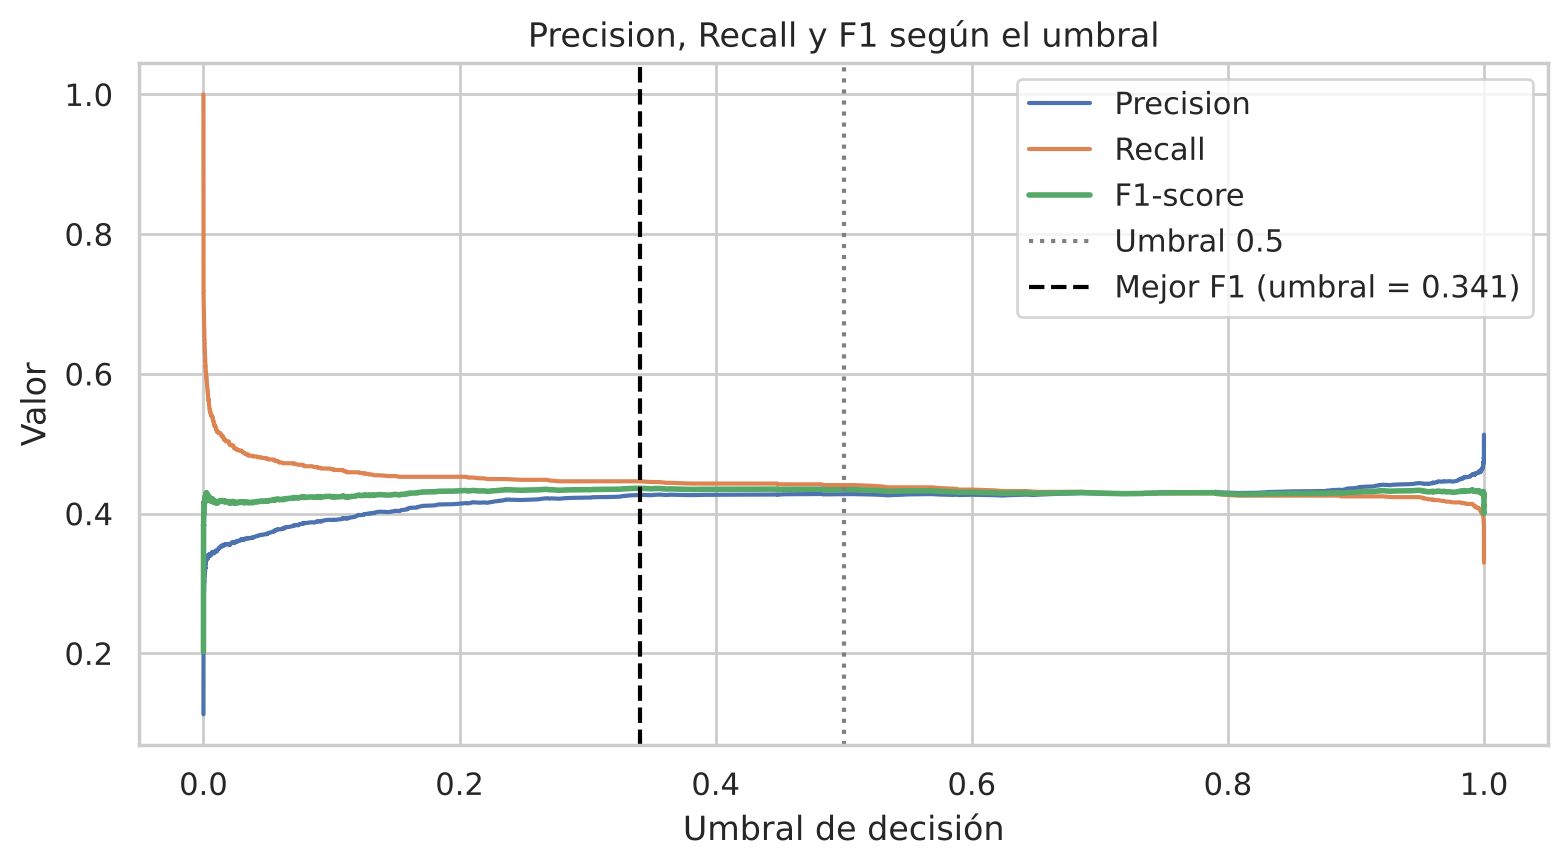

Umbral con mejor F1: 0.3407


In [10]:
precisions, recalls, umbrales = precision_recall_curve(y_test, y_proba)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
mejor = np.argmax(f1s)
umbral_opt = umbrales[mejor]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(umbrales, precisions[:-1], label="Precision")
ax.plot(umbrales, recalls[:-1], label="Recall")
ax.plot(umbrales, f1s, label="F1-score", lw=2)
ax.axvline(0.5, ls=":", color="gray", label="Umbral 0.5")
ax.axvline(umbral_opt, ls="--", color="black", label=f"Mejor F1 (umbral = {umbral_opt:.3f})")
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Valor")
ax.set_title("Precision, Recall y F1 según el umbral")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Umbral con mejor F1: {umbral_opt:.4f}")

**Nota:** en un trabajo real el umbral se debería elegir con un conjunto de validación separado y no con el de prueba. Aquí se usa el de prueba solo para mostrar cómo cambia el comportamiento del modelo al mover el umbral.

In [11]:
y_pred_opt = (y_proba >= umbral_opt).astype(int)
m_opt = metricas(y_test, y_pred_opt, y_proba)

comparacion = pd.DataFrame({"Umbral 0.5": m_base, f"Umbral {umbral_opt:.3f}": m_opt}).round(4)
comparacion

,Umbral 0.5,Umbral 0.341
accuracy,0.8706,0.8701
precision,0.4278,0.4268
recall,0.4407,0.4461
f1,0.4342,0.4362
roc_auc,0.7777,0.7777


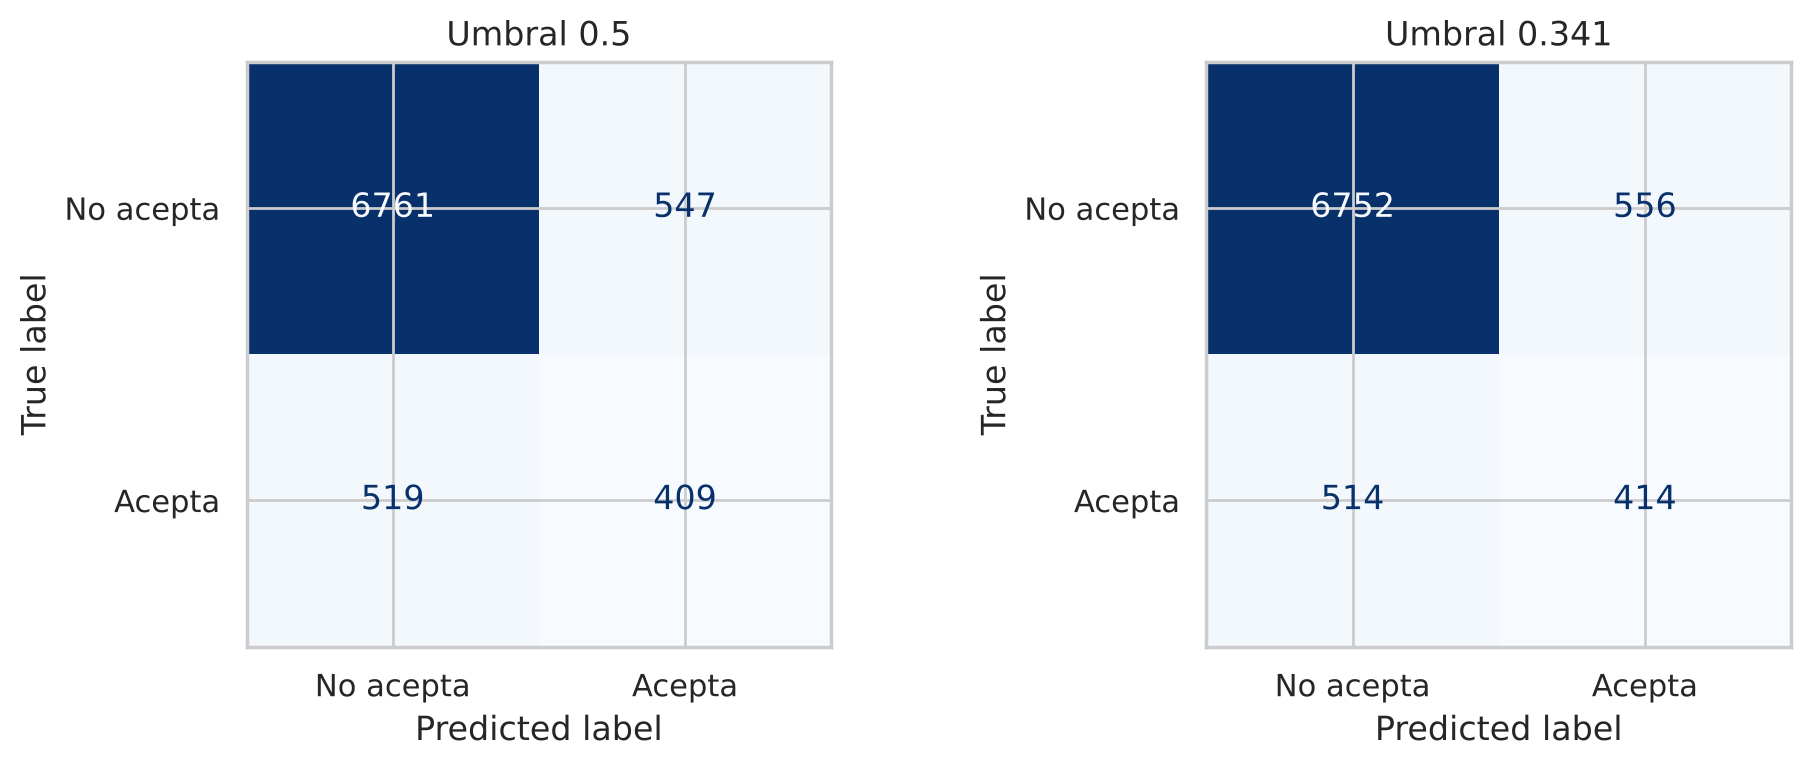

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, titulo in zip(axes, [y_pred, y_pred_opt], ["Umbral 0.5", f"Umbral {umbral_opt:.3f}"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No acepta", "Acepta"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

## 9. Ajuste del hiperparámetro `var_smoothing`

Se prueba con varios valores de `var_smoothing` usando validación cruzada de 5 particiones (*5-fold*) sobre el conjunto de entrenamiento, eligiendo el que da mejor F1.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    modelo,
    param_grid={"nb__var_smoothing": np.logspace(-12, 0, 13)},
    scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

res = pd.DataFrame(grid.cv_results_)[["param_nb__var_smoothing", "mean_test_score", "std_test_score"]]
res.columns = ["var_smoothing", "F1_promedio", "F1_desviacion"]
print("Mejor var_smoothing:", grid.best_params_["nb__var_smoothing"])
tabla = res.copy()
tabla["var_smoothing"] = tabla["var_smoothing"].map(lambda v: f"{float(v):.0e}")
tabla.round(4)

Mejor var_smoothing: 1e-12


,var_smoothing,F1_promedio,F1_desviacion
0,1e-12,0.4294,0.0134
1,1e-11,0.4294,0.0134
2,1e-10,0.4294,0.0134
3,1e-09,0.4294,0.0134
4,1e-08,0.4294,0.0134
5,1e-07,0.4294,0.0134
6,1e-06,0.4294,0.0134
7,1e-05,0.4294,0.0134
8,1e-04,0.4294,0.0134
9,1e-03,0.4294,0.0134


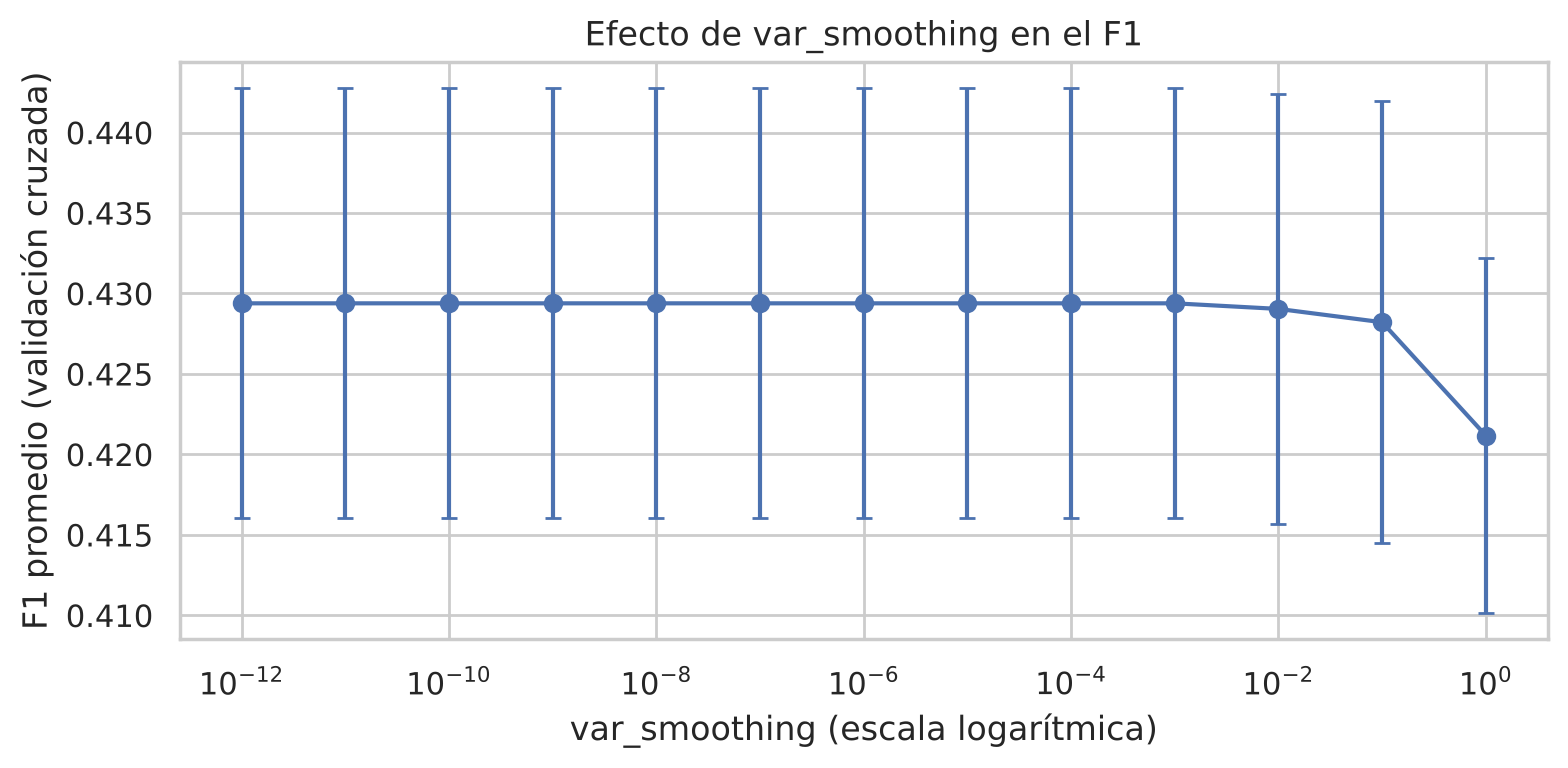

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(res["var_smoothing"].astype(float), res["F1_promedio"], yerr=res["F1_desviacion"], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("var_smoothing (escala logarítmica)")
ax.set_ylabel("F1 promedio (validación cruzada)")
ax.set_title("Efecto de var_smoothing en el F1")
plt.tight_layout()
plt.show()

In [15]:
modelo_final = grid.best_estimator_
y_proba_f = modelo_final.predict_proba(X_test)[:, 1]
y_pred_f = modelo_final.predict(X_test)
m_final = metricas(y_test, y_pred_f, y_proba_f)
pd.Series(m_final).round(4).to_frame("GaussianNB ajustado (umbral 0.5)")

,GaussianNB ajustado (umbral 0.5)
accuracy,0.8706
precision,0.4278
recall,0.4407
f1,0.4342
roc_auc,0.7777


## 10. Efecto de las variables correlacionadas

Como Naive Bayes supone que las variables son independientes, se prueba quitar dos de las tres variables económicas muy correlacionadas (`emp.var.rate` y `nr.employed`) y dejar solo `euribor3m`, para ver si el modelo mejora.

In [16]:
cols_sin = [c for c in X.columns if c not in ["emp.var.rate", "nr.employed"]]
modelo_sin = Pipeline([("scaler", StandardScaler()),
                       ("nb", GaussianNB(var_smoothing=grid.best_params_["nb__var_smoothing"]))])
modelo_sin.fit(X_train[cols_sin], y_train)
y_proba_sin = modelo_sin.predict_proba(X_test[cols_sin])[:, 1]
m_sin = metricas(y_test, modelo_sin.predict(X_test[cols_sin]), y_proba_sin)

pd.DataFrame({"Todas las variables": m_final, "Sin emp.var.rate y nr.employed": m_sin}).round(4)

,Todas las variables,Sin emp.var.rate y nr.employed
accuracy,0.8706,0.8730
precision,0.4278,0.4344
recall,0.4407,0.4213
f1,0.4342,0.4278
roc_auc,0.7777,0.7666


## 11. Validación cruzada del modelo final

Para comprobar que los resultados no dependen de una sola división de los datos, se evalúa el modelo final con validación cruzada de 5 particiones sobre todo el dataset.

In [17]:
cv_res = cross_validate(modelo_final, X, y, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
cv_tabla = pd.DataFrame({
    "promedio": [cv_res[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]],
    "desviacion": [cv_res[f"test_{m}"].std() for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]],
}, index=["accuracy", "precision", "recall", "f1", "roc_auc"]).round(4)
cv_tabla

,promedio,desviacion
accuracy,0.8703,0.0039
precision,0.4263,0.0165
recall,0.4374,0.0166
f1,0.4317,0.0161
roc_auc,0.7678,0.0134


## 12. ¿Qué variables diferencian más a las clases?

GaussianNB guarda la media de cada variable en cada clase ($\mu_{C,i}$). Como los datos están estandarizados, se pueden comparar directamente: mientras más grande sea la diferencia entre la media de los que aceptan y los que no, más ayuda esa variable a separar las clases.

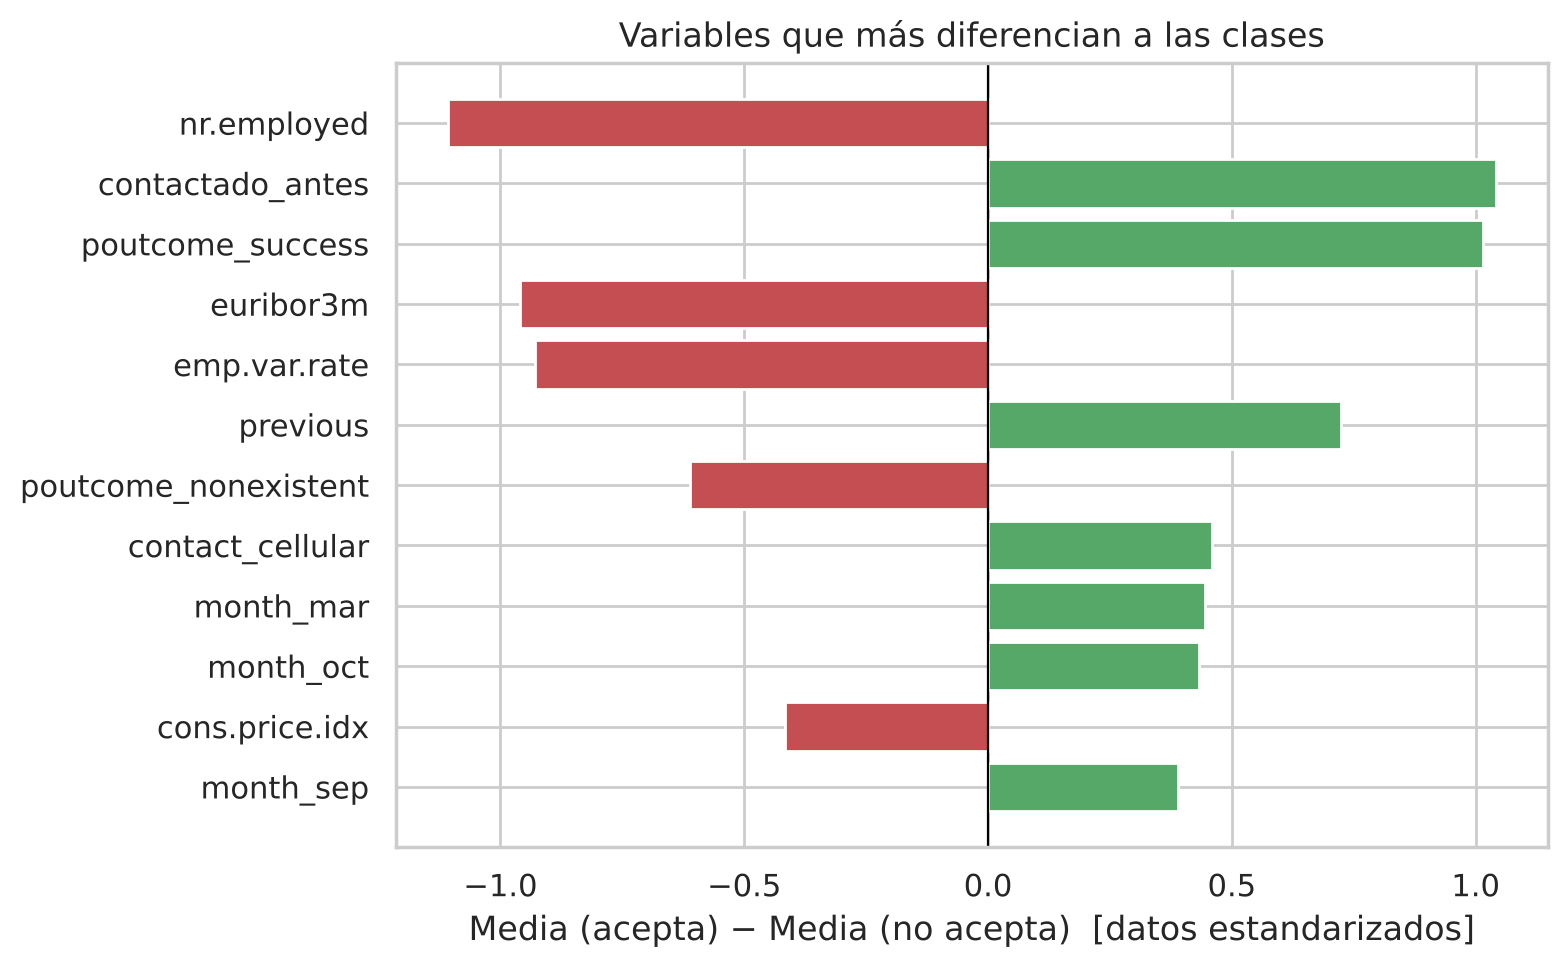

In [18]:
nb_f = modelo_final.named_steps["nb"]
dif = pd.Series(nb_f.theta_[1] - nb_f.theta_[0], index=X.columns)
top = dif.reindex(dif.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
colores = ["#55A868" if v > 0 else "#C44E52" for v in top.values]
ax.barh(top.index[::-1], top.values[::-1], color=colores[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Media (acepta) − Media (no acepta)  [datos estandarizados]")
ax.set_title("Variables que más diferencian a las clases")
plt.tight_layout()
plt.show()

## 13. Guardar resultados para la comparación final

In [19]:
resultados = {
    "modelo": "Gaussian Naive Bayes",
    "var_smoothing": float(grid.best_params_["nb__var_smoothing"]),
    "umbral_optimo": float(umbral_opt),
    "metricas_umbral_05": {k: round(float(v), 4) for k, v in m_final.items()},
    "metricas_umbral_optimo": {k: round(float(v), 4) for k, v in m_opt.items()},
    "baseline_accuracy": round(float(accuracy_score(y_test, y_dummy)), 4),
}
with open("../data/processed/resultados_naive_bayes.json", "w") as f:
    json.dump(resultados, f, indent=2)
resultados

{'modelo': 'Gaussian Naive Bayes',
 'var_smoothing': 1e-12,
 'umbral_optimo': 0.34067522687924706,
 'metricas_umbral_05': {'accuracy': 0.8706,
  'precision': 0.4278,
  'recall': 0.4407,
  'f1': 0.4342,
  'roc_auc': 0.7777},
 'metricas_umbral_optimo': {'accuracy': 0.8701,
  'precision': 0.4268,
  'recall': 0.4461,
  'f1': 0.4362,
  'roc_auc': 0.7777},
 'baseline_accuracy': 0.8873}

## 14. Interpretación de resultados

**Sobre el desempeño:**

1. El modelo base (que siempre dice "no") tiene 88,7% de accuracy pero no detecta a ningún cliente que acepta. Naive Bayes tiene un accuracy un poco menor (87,1%), pero sí encuentra a **44%** de los clientes que aceptan (recall 0,44). Esto demuestra que en este problema el accuracy no es una buena métrica.
2. El **F1 es 0,43** y el **ROC-AUC es 0,78**. El AUC muestra que el modelo ordena bastante mejor que el azar (0,5) a los clientes según su probabilidad de aceptar.
3. La precision es 0,43: de cada 10 clientes que el modelo recomienda llamar, más o menos 4 aceptan. Si se llamara al azar, solo aceptaría 1 de cada 10 (11,3%), así que el modelo **casi cuadruplica la tasa de éxito** de la campaña.
4. Con la validación cruzada de 5 particiones los resultados son parecidos (F1 = 0,43 ± 0,02 y AUC = 0,77 ± 0,01), lo que indica que el modelo es estable y no depende de una sola división de los datos.

**Sobre los parámetros:**

5. **Umbral:** cambiar el umbral casi no mueve los resultados (el mejor F1 pasa de 0,434 a 0,436). En la gráfica se ve que las curvas son casi planas entre 0,05 y 0,95. Esto pasa porque GaussianNB tiende a dar probabilidades muy extremas (cerca de 0 o de 1), un efecto conocido del supuesto de independencia: al multiplicar muchas probabilidades de variables correlacionadas, el modelo "cuenta dos veces" la misma información y se vuelve demasiado seguro.
6. **`var_smoothing`:** todos los valores entre $10^{-12}$ y $10^{-3}$ dan el mismo F1 (0,429), y solo con valores grandes (0,1 o 1) el resultado empeora un poco. Es decir, este hiperparámetro casi no influye en este dataset, porque ninguna variable tiene varianza cercana a cero.
7. **Variables correlacionadas:** quitar `emp.var.rate` y `nr.employed` no mejoró el modelo (el F1 bajó de 0,434 a 0,428 y el AUC de 0,778 a 0,767). Aunque esas variables rompen el supuesto de independencia, también aportan información útil, por eso se mantienen todas.

**Sobre el negocio (variables que más pesan):**

8. Las variables que más separan a los que aceptan de los que no son:
   - **Contexto económico:** cuando `nr.employed`, `euribor3m` y `emp.var.rate` son bajos, los clientes aceptan más.
   - **Historial:** haber sido contactado antes (`contactado_antes`) y haber aceptado en una campaña anterior (`poutcome_success`) aumentan mucho la probabilidad de aceptar.
   - **Canal y mes:** el celular y los meses de marzo, septiembre y octubre se asocian con más aceptación.
   Esto coincide con lo que se encontró en el EDA.

**Limitaciones:**

9. El supuesto de independencia no se cumple (hay variables muy correlacionadas y muchas variables binarias que no siguen una distribución normal), lo que limita el desempeño y hace que las probabilidades no sean muy confiables.
10. El modelo todavía deja sin detectar a 56% de los clientes que sí aceptarían. Para mejorarlo se podrían probar otros modelos (por ejemplo regresión logística o árboles de decisión), aunque esos no son parte del alcance de este escenario.
